# Report 3 — Synthetic simulations (SIMULATED)

**Not real model evidence.** N=400 does not enlarge the real N=30 pilot.

Run `python scripts/eval_report3_synthetic.py` first to regenerate CSVs.

In [5]:
%pip install matplotlib


  Using cached matplotlib-3.11.2-cp311-cp311-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.3.3-cp311-cp311-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp311-cp311-win_amd64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp311-cp311-win_amd64.whl (9.3 MB)
Using cached contourpy-1.3.3-cp311-cp311-win_amd64.whl (225 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   ---------------------------------------- 1.6/1.6 MB 14.9 MB/s  0:00:00
Using cached kiwisolver-1.5.1-cp311-cp311-win_amd64.whl (70 kB)
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   ---------------------------- ----------- 5.2/7.3 MB 24.5 MB/s eta 0:00:01
   ---------------------------------------- 7.3/7.3 MB 22.5 MB/s  0:00:00
Using cached pyparsing-3.3.3-py3-

In [6]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path('.').resolve()
if not (ROOT / 'synthetic_human_esuy_ru_400.csv').exists():
    ROOT = Path('evals/reports/pilot-2026-10/report3_synthetic')

summary = json.loads((ROOT / 'report3_synthetic.json').read_text(encoding='utf-8'))
human = pd.read_csv(ROOT / 'synthetic_human_esuy_ru_400.csv')
judge = pd.read_csv(ROOT / 'synthetic_judge_ru_esuy_400.csv')
print(summary['disclaimer'])
print('human', human['label'].value_counts().to_dict())
print('judge primary', judge['primary_winner'].value_counts().to_dict())
print('power', summary['power_sensitivity'])

All rows are simulated. Do NOT treat N=400 as enlarging the real N=30 pilot. Not evidence of real model superiority.
human {'B_better': 215, 'A_better': 135, 'equal': 50}
judge primary {'equal': 274, 'B_better': 73, 'A_better': 53}
power {'alpha': 0.05, 'target_power': 0.8, 'method': 'monte_carlo_sign_test_ties_dropped', 'small_effect_power_n30': 0.0525, 'small_effect_power_n400': 0.463, 'null_effect_power_n400': 0.049, 'note': 'N=30 real pilot is underpowered for small effects; N=400 is synthetic only.'}


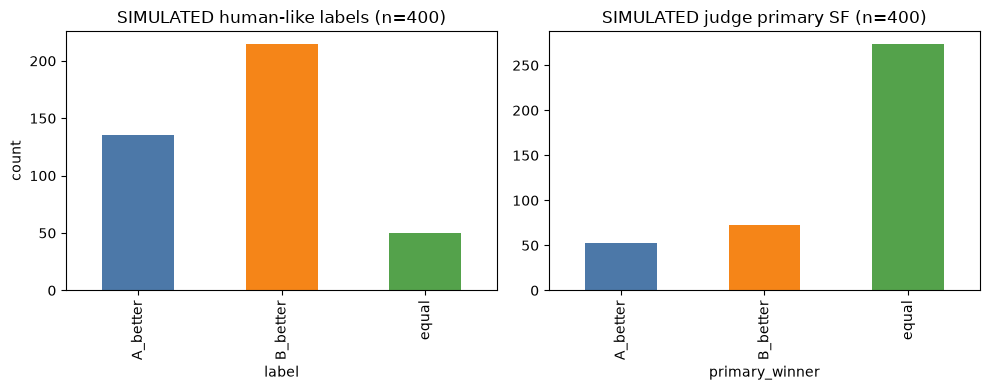

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
human['label'].value_counts().reindex(['A_better','B_better','equal']).plot(
    kind='bar', ax=axes[0], color=['#4C78A8','#F58518','#54A24B']
)
axes[0].set_title('SIMULATED human-like labels (n=400)')
axes[0].set_ylabel('count')
judge['primary_winner'].value_counts().reindex(['A_better','B_better','equal']).plot(
    kind='bar', ax=axes[1], color=['#4C78A8','#F58518','#54A24B']
)
axes[1].set_title('SIMULATED judge primary SF (n=400)')
plt.tight_layout()
plt.show()

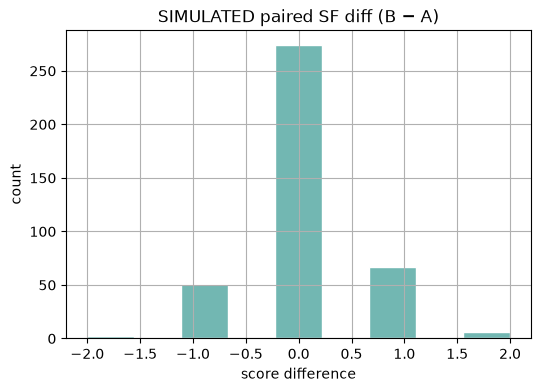

In [8]:
diff = judge['semantic_fidelity_b'] - judge['semantic_fidelity_a']
plt.figure(figsize=(6, 4))
diff.hist(bins=9, color='#72B7B2', edgecolor='white')
plt.title('SIMULATED paired SF diff (B − A)')
plt.xlabel('score difference')
plt.ylabel('count')
plt.show()